# Strategic Market Selection & Risk-Aware Unit Mix Optimization  
**Skyline Capital Partners – Class B Development Analysis**  
Tanay Gupta  
GBA 478P  
February 28, 2026  

---

## Executive Summary

This analysis evaluates three potential markets (Fairview, New Hope, and Springfield) for a new Class B apartment development. Markets are compared using risk-adjusted return metrics, including mean IRR, volatility, and downside percentiles.

New Hope is identified as the strongest market, delivering the highest expected IRR (8.8%) and the strongest downside protection (5th percentile IRR = 4.37%).

An 85-unit development is then optimized using Monte Carlo simulation under structural, demand, and cost constraints. The final recommended mix (55 Studios / 30 One-Bedrooms) maximizes expected profit while maintaining a ≤10% probability of loss and demonstrating resilience under stress testing.

## Data Availability and Reproducibility

This portfolio notebook was developed using `CRE_Data_SpringA2026.xlsx`, a dataset provided for academic coursework. **The original workbook is not included in the public repository because redistribution permission has not been confirmed.**

The code is retained to document the analytical workflow, but running the notebook end-to-end requires authorized access to the workbook in the notebook's working directory. Saved **aggregate** market comparisons, optimization results, simulation summaries, and charts are provided for review; these are historical notebook outputs, not a substitute for rerunning the analysis.

Individual source-data previews have been removed from the public-facing notebook. Please do not interpret simulated zero observed losses as a guarantee of no investment risk.


## 1. Data Loading and Structure Verification

This section loads the historical dataset for 300 apartment buildings across three cities (Fairview, New Hope, and Springfield).

The data includes:
- Building characteristics (unit mix, rent levels)
- 5-year financial performance (NOI, vacancy, expenses)
- Initial equity investment and equity reversion values

The dataset structure is verified before proceeding with analysis.

In [ ]:
import pandas as pd
import numpy as np

DATA_PATH = "CRE_Data_SpringA2026.xlsx"

# Load Excel file and inspect sheet names
xl = pd.ExcelFile(DATA_PATH)
print("Sheets:", xl.sheet_names)

# Load required sheets
buildings  = pd.read_excel(DATA_PATH, sheet_name="Buildings")
financials = pd.read_excel(DATA_PATH, sheet_name="Financials")
equity     = pd.read_excel(DATA_PATH, sheet_name="Equity")

# Display dataset dimensions
print("\nDataset Shapes:")
print("Buildings:", buildings.shape)
print("Financials:", financials.shape)
print("Equity:", equity.shape)

# Display column names for validation
print("\nBuildings Columns:\n", buildings.columns.tolist())
print("\nFinancials Columns:\n", financials.columns.tolist())
print("\nEquity Columns:\n", equity.columns.tolist())

buildings.head()

## 2. Operating Risk Analysis Across Markets

Before evaluating capital returns, we examine operating risk drivers across the three cities.

Key operating risk metrics include:

- Vacancy rate (Lost Rent / Gross Rental Income)
- Operating expense ratio (Operating Expenses / Effective Gross Income)
- Average Net Operating Income (NOI)
- NOI volatility
- Coefficient of variation (NOI volatility relative to average NOI)

This step identifies whether higher returns are driven by excessive operational instability.

In [2]:
# Create working copy of financial data
fin = financials.copy()
fin.columns = fin.columns.str.strip()

# Compute operating risk metrics
fin["vacancy_rate"] = fin["Lost Rent"] / fin["Gross Rental Income"]
fin["opex_ratio"]   = fin["Operating Expenses"] / fin["Effective Gross Income"]

# Aggregate city-level operating statistics
city_risk = fin.groupby("City").agg(
    vacancy_mean=("vacancy_rate", "mean"),
    vacancy_std=("vacancy_rate", "std"),
    opex_mean=("opex_ratio", "mean"),
    opex_std=("opex_ratio", "std"),
    noi_mean=("Net Operating Income", "mean"),
    noi_std=("Net Operating Income", "std"),
).round(4)

# Compute coefficient of variation (NOI risk per dollar of return)
city_risk["noi_cv"] = city_risk["noi_std"] / city_risk["noi_mean"]

city_risk.sort_values("noi_mean", ascending=False).style.format({
    "vacancy_mean": "{:.2%}",
    "vacancy_std": "{:.2%}",
    "opex_mean": "{:.2%}",
    "opex_std": "{:.2%}",
    "noi_mean": "{:,.0f}",
    "noi_std": "{:,.0f}",
    "noi_cv": "{:.3f}"
})

,vacancy_mean,vacancy_std,opex_mean,opex_std,noi_mean,noi_std,noi_cv
City,,,,,,,
New Hope,10.18%,2.83%,50.48%,4.40%,"1,108,207","481,473",0.434
Springfield,10.08%,2.90%,52.01%,4.34%,"962,399","413,987",0.430
Fairview,9.86%,3.00%,57.37%,4.26%,"906,159","385,124",0.425


## 3. Market Selection: Risk-Adjusted Return (IRR) Analysis

To compare the three markets on a capital-return basis, IRR is computed for each building using a 5-year holding period cash flow structure:

- Year 1: Initial equity investment + operating cash flow
- Years 2-4: Operating cash flow
- Year 5: Operating cash flow + equity reversion (sale proceeds)

Operating cash flow is approximated as:
**EBT = NOI - (Interest & Depreciation)**  
with **Interest & Depreciation estimated at 5% of NOI**, consistent with the provided profitability framework.

Markets are compared using:
- Mean IRR (expected return)
- Std dev IRR (volatility)
- P05 / P10 IRR (downside risk)

In [3]:
import numpy_financial as npf
import numpy as np

# Pivot NOI by year (ensure Year columns are 1..5)
noi_p = fin.pivot_table(
    index=["City", "Building ID", "Class"],
    columns="Year",
    values="Net Operating Income",
    aggfunc="first"
).reset_index()

# Rename NOI columns explicitly
noi_p = noi_p.rename(columns={y: f"NOI_Y{y}" for y in [1,2,3,4,5]})

# Clean equity table and align key
eq = equity.copy()
eq.columns = eq.columns.str.strip()
eq = eq.rename(columns={"Building": "Building ID"})

# Merge NOI + equity
df = noi_p.merge(eq, on=["City", "Building ID"], how="left")

# Compute IRR per building (5-year hold)
def compute_irr(row):
    ebt = [0.95 * row[f"NOI_Y{y}"] for y in [1,2,3,4,5]]  # EBT = NOI * (1 - 0.05)
    cash_flows = [
        -row["Initial Equity Investment"] + ebt[0],
        ebt[1],
        ebt[2],
        ebt[3],
        ebt[4] + row["Equity Reversion"]
    ]
    return npf.irr(cash_flows)

df["irr"] = df.apply(compute_irr, axis=1)

# City-level IRR comparison (return + risk + downside)
city_returns = df.groupby("City").agg(
    irr_mean=("irr", "mean"),
    irr_std=("irr", "std"),
    irr_p05=("irr", lambda x: np.quantile(x, 0.05)),
    irr_p10=("irr", lambda x: np.quantile(x, 0.10)),
).round(4).sort_values("irr_mean", ascending=False)

city_returns.style.format({
    "irr_mean": "{:.2%}",
    "irr_std": "{:.2%}",
    "irr_p05": "{:.2%}",
    "irr_p10": "{:.2%}"
})

,irr_mean,irr_std,irr_p05,irr_p10
City,,,,
New Hope,8.80%,3.10%,4.37%,4.73%
Fairview,5.90%,1.93%,3.29%,3.63%
Springfield,5.08%,1.74%,2.96%,3.24%


**Decision:** Select the market with the strongest risk-adjusted profile, emphasizing both expected return and downside protection (P05 / P10).

## 4. Simulation Inputs (Selected Market: New Hope, Class B)

After selecting **New Hope** as the recommended market, the unit-mix optimization is calibrated using historical **Class B** data from that city.

Simulation inputs are constructed using empirical distributions:

- **Studio and 1BR rent levels (Year 1)** from historical Class B properties  
- **Vacancy rates** from historical Class B financial performance (Lost Rent / Gross Rental Income)

These empirical distributions are used directly in Monte Carlo simulation to capture realistic market uncertainty without imposing parametric assumptions.

In [4]:
SELECTED_CITY = "New Hope"

# Filter to Class B properties in the selected city
b_cityB = buildings.query("City == @SELECTED_CITY and Class == 'B'").copy()

# Empirical rent distributions (Year 1) from Buildings table
studio_rent_dist = b_cityB["Studio Rent"].dropna().to_numpy()
onebr_rent_dist  = b_cityB["1-Bedroom Rent"].dropna().to_numpy()

# Empirical vacancy distribution from Financials: vacancy = Lost Rent / Gross Rental Income
fin_cityB = fin.query("City == @SELECTED_CITY and Class == 'B'").copy()
vacancy_dist = (fin_cityB["Lost Rent"] / fin_cityB["Gross Rental Income"]).dropna().to_numpy()

print(f"N rent samples (Studio, 1BR): {len(studio_rent_dist)}, {len(onebr_rent_dist)}")
print("N vacancy samples:", len(vacancy_dist))

print("Studio rent range: ${:,.0f} – ${:,.0f}".format(
    studio_rent_dist.min(), studio_rent_dist.max()
))

print("1BR rent range: ${:,.0f} – ${:,.0f}".format(
    onebr_rent_dist.min(), onebr_rent_dist.max()
))

print("Vacancy range: {:.2%} – {:.2%}".format(
    vacancy_dist.min(), vacancy_dist.max()
))

N rent samples (Studio, 1BR): 44, 44
N vacancy samples: 220
Studio rent range: $1,278 – $2,208
1BR rent range: $1,789 – $3,092
Vacancy range: 5.18% – 14.85%


These distributions form the stochastic drivers in the unit mix simulation: rent determines both revenue and demand caps, while vacancy introduces revenue loss risk.

## 5. Development Constraints and Demand Modeling

The proposed Class B development must satisfy structural and financial constraints from the Skyline memo:

**Structural Constraints**
- Total units: 85
- Maximum floor area: 80,000 sq ft
- Studio size: 800 sq ft
- 1-Bedroom size: 1,200 sq ft

**Cost Structure**
- Fixed annual operating cost: $320,000
- Studio variable cost: $720/month
- 1BR variable cost: $1,000/month

**Demand Constraints**
Demand is limited by rent-tier market absorption caps.  
For each simulated rent level, maximum achievable leased units are restricted based on historical rent buckets.

These constraints are enforced directly within the simulation model.

In [5]:
# ================================
# Structural & Cost Constraints
# ================================

TOTAL_UNITS = 85
TOTAL_SF = 80_000
STUDIO_SF = 800
ONEBR_SF = 1_200

FIXED_COST_YR = 320_000
STUDIO_VAR_COST_MO = 720
ONEBR_VAR_COST_MO  = 1_000


# ================================
# Demand Caps (Rent-Tier Limits)
# ================================

# Format: (lower_rent, upper_rent, max_studios, max_1BR)
demand_table = [
    (-np.inf, 1500, 60, 75),
    (1500, 1800, 55, 70),
    (1800, 2100, 48, 65),
    (2200, 2500, 40, 57),
    (2500, 2800, 30, 48),
    (2800, 3100, 18, 35),
]

def demand_caps(rent):
    for lo, hi, cap_s, cap_b in demand_table:
        if lo <= rent < hi:
            return cap_s, cap_b
    # Conservative handling of 2100–2200 rent gap
    if 2100 <= rent < 2200:
        return 48, 65
    # Above highest bucket → tightest cap
    return 18, 35


def space_feasible(studios, onebrs):
    return (
        studios + onebrs == TOTAL_UNITS and
        studios * STUDIO_SF + onebrs * ONEBR_SF <= TOTAL_SF
    )

## 6. Monte Carlo Profit Simulation

To evaluate each feasible unit mix under uncertainty, a Monte Carlo simulation is implemented.

For each simulation trial:

1. Studio and 1BR rents are sampled from empirical historical distributions.
2. Vacancy rates are sampled from historical Class B performance.
3. Demand caps are applied based on simulated rent tiers.
4. Leased units are constrained by both demand limits and vacancy risk.
5. Annual revenue and operating costs are calculated.
6. Profit is computed as Revenue − Operating Costs.

Each unit mix is evaluated using 20,000 simulation trials to estimate:
- Expected annual profit
- Profit volatility
- Downside percentiles
- Probability of loss

In [6]:
def simulate_annual_profit(studios, onebrs, n_sims=10000, seed=123):
    # Ensure structural feasibility
    assert space_feasible(studios, onebrs)

    rng = np.random.default_rng(seed)

    # -----------------------------
    # Sample stochastic drivers
    # -----------------------------
    s_rent = rng.choice(studio_rent_dist, size=n_sims, replace=True)
    b_rent = rng.choice(onebr_rent_dist,  size=n_sims, replace=True)
    vac    = rng.choice(vacancy_dist,     size=n_sims, replace=True)

    # -----------------------------
    # Apply demand caps (rent-tier)
    # -----------------------------
    studio_caps = np.array([demand_caps(r)[0] for r in s_rent])
    onebr_caps = np.array([demand_caps(r)[1] for r in b_rent])

    cap_s = studio_caps
    cap_b = onebr_caps

    lease_s = np.minimum(studios, cap_s)
    lease_b = np.minimum(onebrs,  cap_b)

    # -----------------------------
    # Apply vacancy risk
    # -----------------------------
    lease_s = np.floor(lease_s * (1 - vac))
    lease_b = np.floor(lease_b * (1 - vac))

    # -----------------------------
    # Revenue & cost calculation
    # -----------------------------
    revenue = lease_s * s_rent * 12 + lease_b * b_rent * 12

    costs = (
        FIXED_COST_YR
        + studios * STUDIO_VAR_COST_MO * 12
        + onebrs  * ONEBR_VAR_COST_MO  * 12
    )

    profit = revenue - costs
    return profit

## 7. Risk-Constrained Unit Mix Optimization

All feasible unit mixes are evaluated under Skyline’s structural constraints (85 units, 80,000 sq ft) and demand caps.

Objective:
- **Maximize expected annual profit**

Risk constraint:
- **Probability of loss ≤ 10%**

Each feasible mix is simulated using **20,000 Monte Carlo trials** and scored using:
- Mean profit (expected return)
- Std dev profit (volatility)
- P05 / P10 profit (downside outcomes)
- Probability of loss (tail risk measure)

In [7]:
LOSS_THRESHOLD = 0.10
N_SIMS = 20000  # stable tail stats, still runs fine
rows = []

for studios in range(TOTAL_UNITS + 1):
    onebrs = TOTAL_UNITS - studios
    if not space_feasible(studios, onebrs):
        continue

    prof = simulate_annual_profit(studios, onebrs, n_sims=N_SIMS, seed=123)

    mean = prof.mean()
    std  = prof.std()
    p05  = np.quantile(prof, 0.05)
    p10  = np.quantile(prof, 0.10)
    p_loss = (prof < 0).mean()

    rows.append({
        "studios": studios,
        "onebrs": onebrs,
        "mean_profit": mean,
        "std_profit": std,
        "p05_profit": p05,
        "p10_profit": p10,
        "p_loss": p_loss,
        "space_used": studios*STUDIO_SF + onebrs*ONEBR_SF
    })

res = pd.DataFrame(rows)

# Feasible set under the risk constraint
feasible = res[res["p_loss"] <= LOSS_THRESHOLD].copy()

best = feasible.sort_values("mean_profit", ascending=False).head(1)

print("Number of feasible mixes under risk constraint:", feasible.shape[0])
best.style.format({
    "mean_profit": "{:,.0f}",
    "std_profit": "{:,.0f}",
    "p05_profit": "{:,.0f}",
    "p10_profit": "{:,.0f}",
    "p_loss": "{:.2%}"
})

Number of feasible mixes under risk constraint: 24


,studios,onebrs,mean_profit,std_profit,p05_profit,p10_profit,p_loss,space_used
0,55,30,"644,529","122,340","435,570","487,561",0.00%,80000


In [8]:
top3 = feasible.sort_values("mean_profit", ascending=False).head(3)

top3[["studios","onebrs","mean_profit","std_profit","p05_profit","p_loss"]].style.format({
    "mean_profit": "{:,.0f}",
    "std_profit": "{:,.0f}",
    "p05_profit": "{:,.0f}",
    "p_loss": "{:.2%}"
})

,studios,onebrs,mean_profit,std_profit,p05_profit,p_loss
0,55,30,"644,529","122,340","435,570",0.00%
1,56,29,"621,327","119,090","419,426",0.00%
2,57,28,"597,278","115,018","401,431",0.00%


Among the top risk-compliant configurations, the 55/30 mix delivers the highest expected profit while maintaining a zero observed loss frequency and the strongest downside protection (P05 profit). 

Higher studio concentrations marginally reduce volatility but at the cost of materially lower expected returns and weaker downside floors.

### 7.1 Baseline Performance of Recommended Mix (55 Studios / 30 1BR)

The selected unit mix is evaluated under baseline market conditions using 20,000 Monte Carlo trials.

Key performance metrics:

- Mean annual profit (expected return)
- Profit volatility (standard deviation)
- Probability of loss (tail risk measure)
- 5th percentile profit (downside protection)

In [9]:
base_profit = simulate_annual_profit(55, 30, n_sims=20000, seed=123)

base_results = {
    "Mean Profit": base_profit.mean(),
    "Std Dev Profit": base_profit.std(),
    "Probability of Loss": (base_profit < 0).mean(),
    "P05 Profit": np.quantile(base_profit, 0.05)
}

pd.DataFrame(base_results, index=["Baseline"]).round(0)

,Mean Profit,Std Dev Profit,Probability of Loss,P05 Profit
Baseline,644529.0,122340.0,0.0,435570.0


Under baseline conditions, the recommended mix generates strong expected profitability with 0% observed loss frequency across 20,000 simulated scenarios.

## 8. Risk–Return Visualization

To illustrate the tradeoff across feasible unit mixes:

1. A risk–return frontier is plotted (Mean Profit vs. Profit Volatility).
2. Probability of loss is plotted against studio concentration.

These visualizations highlight how increasing studio allocation affects expected return and downside risk.

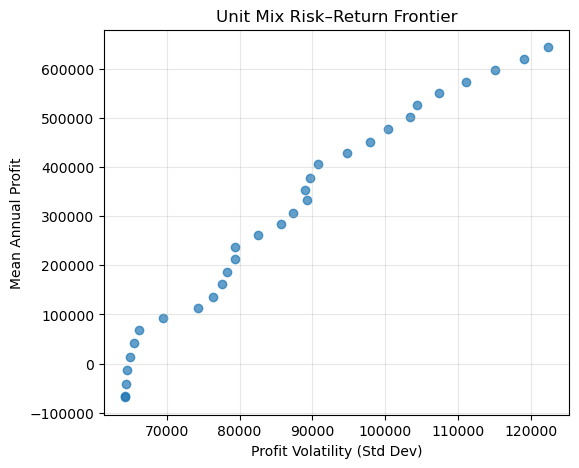

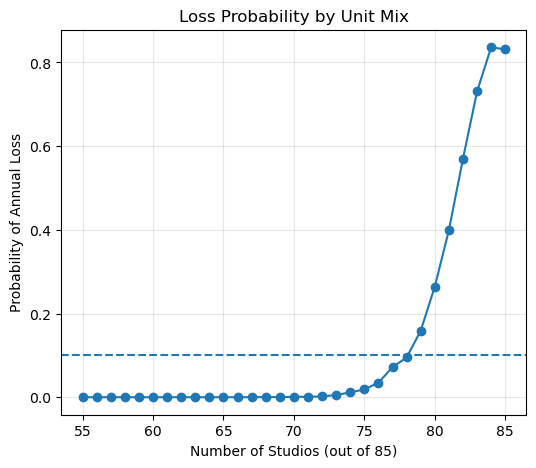

In [10]:
import matplotlib.pyplot as plt

# -----------------------------
# Plot 1: Risk–Return Frontier
# -----------------------------
plt.figure(figsize=(6,5))
plt.scatter(res["std_profit"], res["mean_profit"], alpha=0.7)
plt.xlabel("Profit Volatility (Std Dev)")
plt.ylabel("Mean Annual Profit")
plt.title("Unit Mix Risk–Return Frontier")
plt.grid(alpha=0.3)
plt.show()


# -----------------------------
# Plot 2: Probability of Loss
# -----------------------------
plt.figure(figsize=(6,5))
plt.plot(res["studios"], res["p_loss"], marker='o')
plt.axhline(LOSS_THRESHOLD, linestyle="--")
plt.xlabel("Number of Studios (out of 85)")
plt.ylabel("Probability of Annual Loss")
plt.title("Loss Probability by Unit Mix")
plt.grid(alpha=0.3)
plt.show()

The risk–return frontier demonstrates that increasing studio concentration increases expected profit but also increases volatility.

The loss probability curve reveals nonlinear tail risk behavior: beyond approximately 78 studios, the probability of loss rises sharply, indicating concentration-driven downside exposure.

## 9. Stress Testing: Vacancy Shock Scenario

To evaluate robustness, the recommended unit mix is tested under a stress scenario.

Assumption:
- Vacancy rates increase by +2 percentage points across all simulations.

This sensitivity analysis evaluates whether the proposed configuration remains profitable under moderate demand deterioration.

In [11]:
def simulate_with_vacancy_shock(studios, onebrs, vacancy_shock=0.02, n_sims=10000, seed=123):
    # Temporarily modify vacancy distribution
    rng = np.random.default_rng(seed)

    s_rent = rng.choice(studio_rent_dist, size=n_sims, replace=True)
    b_rent = rng.choice(onebr_rent_dist,  size=n_sims, replace=True)

    vac = rng.choice(vacancy_dist, size=n_sims, replace=True) + vacancy_shock
    vac = np.clip(vac, 0, 1)

    studio_caps = np.array([demand_caps(r)[0] for r in s_rent])
    onebr_caps = np.array([demand_caps(r)[1] for r in b_rent])

    cap_s = studio_caps
    cap_b = onebr_caps

    lease_s = np.minimum(studios, cap_s)
    lease_b = np.minimum(onebrs,  cap_b)

    lease_s = np.floor(lease_s * (1 - vac))
    lease_b = np.floor(lease_b * (1 - vac))

    revenue = lease_s * s_rent * 12 + lease_b * b_rent * 12

    costs = (
        FIXED_COST_YR
        + studios * STUDIO_VAR_COST_MO * 12
        + onebrs  * ONEBR_VAR_COST_MO  * 12
    )

    return revenue - costs

### 9.1 Stress Test Results (55 Studios / 30 1BR)

The recommended unit mix is evaluated under a +2% vacancy shock using 20,000 Monte Carlo trials.

The following metrics are reported:

- Mean annual profit
- Profit volatility (standard deviation)
- Probability of loss
- 5th percentile profit (downside protection)

In [12]:
shock_profit = simulate_with_vacancy_shock(
    studios=55,
    onebrs=30,
    vacancy_shock=0.02,
    n_sims=20000
)

stress_results = {
    "Mean Profit": shock_profit.mean(),
    "Std Dev Profit": shock_profit.std(),
    "Probability of Loss": (shock_profit < 0).mean(),
    "P05 Profit": np.quantile(shock_profit, 0.05)
}

pd.DataFrame(stress_results, index=["Stress (+2% Vacancy)"]).round(0)

,Mean Profit,Std Dev Profit,Probability of Loss,P05 Profit
Stress (+2% Vacancy),603347.0,117927.0,0.0,399554.0


Under the vacancy stress scenario:

- Expected profit declines moderately relative to baseline.
- No losses were observed across the 20,000 simulated stress scenarios; this does not imply that real-world losses are impossible.
- Downside protection remains strong (P05 > $390K).

This confirms the recommended mix is robust to moderate demand deterioration.

## 10. Final Recommendation

**Market Selection:** Develop in **New Hope** based on the strongest risk-adjusted return profile (highest mean IRR and strongest downside IRR floor).

**Unit Mix Recommendation:** **55 Studios / 30 One-Bedrooms**

This configuration:
- Maximizes expected annual profit under the **≤10% probability-of-loss constraint**
- Provides strong downside protection (P05 profit remains strongly positive)
- Demonstrates robustness under a **+2% vacancy stress test**
- Balances return potential with disciplined risk control